In [19]:
import glob
from importlib.resources import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Local downloaded files
# files = sorted(glob.glob("yellow_tripdata_2025-*.parquet"))

# print(len(files))
# print(files)
# df = pd.concat(
#     [pd.read_parquet(file) for file in files],
#     ignore_index=True
# )

# print(df.shape)

dfs = []

for month in range(1, 13):
    url = (
        "https://d37ci6vzurychx.cloudfront.net/trip-data/"
        f"yellow_tripdata_2025-{month:02d}.parquet"
    )
    dfs.append(pd.read_parquet(url))

df = pd.concat(dfs, ignore_index=True)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

In [20]:
#print(df.columns.tolist())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48722602 entries, 0 to 48722601
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64 

In [21]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,48722602.00,48722602,48722602,37110708.00,48722602.00,37110708.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,48722602.00,37110708.00,37110708.00,48722602.00
mean,1.86,2025-07-06 05:22:36.621956,2025-07-06 05:39:57.973506,1.30,6.84,3.23,161.50,161.11,0.94,18.42,1.16,0.48,2.84,0.50,0.95,26.91,2.18,0.15,0.53
min,1.00,2007-12-05 18:45:00,2007-12-05 19:02:00,0.00,0.00,1.00,1.00,1.00,0.00,-1807.60,-17.39,-21.74,-333.33,-148.17,-1.00,-1832.85,-2.50,-1.75,-0.75
25%,2.00,2025-04-08 14:04:38,2025-04-08 14:21:56,1.00,1.04,1.00,114.00,107.00,1.00,8.60,0.00,0.50,0.00,0.00,1.00,15.73,2.50,0.00,0.00
50%,2.00,2025-07-03 12:25:13,2025-07-03 12:42:35,1.00,1.85,1.00,161.00,162.00,1.00,13.58,0.00,0.50,2.00,0.00,1.00,21.35,2.50,0.00,0.75
75%,2.00,2025-10-06 13:54:53.750000,2025-10-06 14:13:21.750000,1.00,3.70,1.00,233.00,233.00,1.00,22.60,2.50,0.50,3.99,0.00,1.00,30.75,2.50,0.00,0.75
max,7.00,2025-12-31 23:59:59,2026-01-05 13:00:34,9.00,397994.37,99.00,265.00,265.00,5.00,863372.12,133.60,5243.38,960.94,916.87,2.50,863380.37,2.50,6.75,1.75
std,0.68,NaN,NaN,0.73,649.36,14.27,66.20,70.45,0.75,142.85,1.82,0.76,3.97,2.12,0.28,143.48,0.95,0.53,0.36


In [22]:
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["pickup_month"] = df["tpep_pickup_datetime"].dt.month
df["pickup_day"] = df["tpep_pickup_datetime"].dt.day

df["duration_min"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["fare_per_mile"] = (
    df["fare_amount"] / df["trip_distance"]
).replace([float("inf"), -float("inf")], float("nan"))

df["speed_mph"] = (
    df["trip_distance"] / (df["duration_min"] / 60)
).replace([float("inf"), -float("inf")], float("nan"))

df.drop(
    columns=["tpep_pickup_datetime", "tpep_dropoff_datetime"],
    inplace=True
)
pd.options.display.float_format = '{:.2f}'.format
clean = df[
    (df["duration_min"] > 0) &
    (df["fare_amount"] > 0) &
    (df["trip_distance"] > 0) &
    (df["speed_mph"] > 0)
].copy()



In [23]:
clean.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,...,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_month,pickup_day,duration_min,fare_per_mile,speed_mph
count,44171935.00,35325361.00,44171935.00,35325361.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,...,44171935.00,35325361.00,35325361.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00
mean,1.79,1.29,6.59,3.27,162.06,161.69,0.94,20.07,1.29,0.50,...,28.89,2.28,0.15,0.55,14.21,6.62,15.58,17.62,19.38,23.47
std,0.42,0.73,616.34,14.46,65.78,70.28,0.65,149.67,1.84,0.79,...,150.21,0.70,0.50,0.33,5.99,3.44,8.70,27.47,222.32,3045.48
min,1.00,0.00,0.01,1.00,1.00,1.00,0.00,0.01,-17.39,-21.74,...,0.00,0.00,0.00,-0.75,0.00,1.00,1.00,0.02,0.00,0.00
25%,2.00,1.00,1.10,1.00,122.00,108.00,1.00,9.30,0.00,0.50,...,16.75,2.50,0.00,0.00,10.00,4.00,8.00,8.30,5.56,6.99
50%,2.00,1.00,1.89,1.00,161.00,162.00,1.00,14.20,0.00,0.50,...,22.04,2.50,0.00,0.75,15.00,7.00,15.00,13.53,7.22,9.44
75%,2.00,1.00,3.73,1.00,233.00,234.00,1.00,23.33,2.50,0.50,...,31.60,2.50,0.00,0.75,19.00,10.00,23.00,21.53,9.38,13.04
max,6.00,9.00,397994.37,99.00,265.00,265.00,5.00,863372.12,42.46,5243.38,...,863380.37,2.50,5.00,1.50,23.00,12.00,31.00,14880.77,539607.57,4034270.10


In [24]:
impossible_values = clean[
    (clean["fare_amount"] > 100) |
    (clean["fare_per_mile"] > 10) |
    (clean["duration_min"] > 120) |
    (clean["speed_mph"] == 75)]
impossible_values.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,...,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_month,pickup_day,duration_min,fare_per_mile,speed_mph
count,9084078.00,7505721.00,9084078.00,7505721.00,9084078.00,9084078.00,9084078.00,9084078.00,9084078.00,9084078.00,...,9084078.00,7505721.00,7505721.00,9084078.00,9084078.00,9084078.00,9084078.00,9084078.00,9084078.00,9084078.00
mean,1.80,1.29,1.48,2.26,168.50,167.66,1.01,16.12,1.11,0.49,...,23.82,2.35,0.03,0.58,14.37,7.07,15.44,14.96,69.00,6.57
std,0.40,0.73,91.13,10.59,62.48,64.14,0.69,328.43,1.57,0.07,...,328.65,0.59,0.22,0.32,4.88,3.51,8.56,53.94,487.06,315.06
min,1.00,0.00,0.01,1.00,1.00,1.00,0.00,0.01,-17.39,-6.38,...,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.02,0.00,0.00
25%,2.00,1.00,0.53,1.00,137.00,138.00,1.00,7.20,0.00,0.50,...,14.30,2.50,0.00,0.75,11.00,4.00,8.00,5.68,10.89,4.16
50%,2.00,1.00,0.80,1.00,163.00,163.00,1.00,11.40,0.00,0.50,...,18.50,2.50,0.00,0.75,15.00,7.00,15.00,10.00,12.31,5.29
75%,2.00,1.00,1.25,1.00,233.00,233.00,1.00,17.00,2.50,0.50,...,24.84,2.50,0.00,0.75,18.00,10.00,23.00,16.53,15.26,6.85
max,6.00,9.00,131394.19,99.00,265.00,265.00,4.00,863372.12,42.46,22.14,...,863380.37,2.50,1.75,1.50,23.00,12.00,31.00,14880.77,539607.57,702497.15


We have impossible values here, so we will drop any trips over 25 miles, which is an aribtrarily reasonable maximum (far greater than the 75% percentile). A trip of 0.01 is not very informative for predictions, so we arbitrarily choose 0.2 as our reasonable minimum. 

Remove incredibly unlikely average speeds, fare costs, and trip durations, then check how much data we lost. 

In [25]:
analysis = clean[
    (clean["speed_mph"] > 0) &
    (clean["speed_mph"] <= 40) &
    (clean["trip_distance"] > .2) &
    (clean["trip_distance"] <= 25) &
    (clean["fare_amount"] > 0) &
    (clean["fare_amount"] <= 100) &
    (clean["duration_min"] >= 1) &
    (clean["total_amount"] <= 125)
].copy()

print("Clean rows:", len(analysis))
print(
    "Percent retained:",
    len(analysis) / len(clean) * 100
)
analysis.describe()

Clean rows: 43377188
Percent retained: 98.20078744569373


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,...,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_month,pickup_day,duration_min,fare_per_mile,speed_mph
count,43377188.00,34750146.00,43377188.00,34750146.00,43377188.00,43377188.00,43377188.00,43377188.00,43377188.00,43377188.00,...,43377188.00,34750146.00,34750146.00,43377188.00,43377188.00,43377188.00,43377188.00,43377188.00,43377188.00,43377188.00
mean,1.79,1.29,3.39,3.26,162.22,161.83,0.94,19.43,1.30,0.50,...,28.15,2.30,0.15,0.55,14.21,6.61,15.58,17.51,8.02,10.89
std,0.42,0.72,3.95,14.50,65.85,70.01,0.64,15.22,1.84,0.04,...,19.10,0.67,0.49,0.33,5.99,3.44,8.70,27.04,5.02,5.91
min,1.00,0.00,0.21,1.00,1.00,1.00,0.00,0.01,-17.39,-21.74,...,0.00,0.00,0.00,-0.75,0.00,1.00,1.00,1.00,0.00,0.00
25%,2.00,1.00,1.10,1.00,116.00,112.00,1.00,9.30,0.00,0.50,...,16.76,2.50,0.00,0.00,10.00,4.00,8.00,8.35,5.57,7.03
50%,2.00,1.00,1.90,1.00,161.00,162.00,1.00,14.20,0.00,0.50,...,21.95,2.50,0.00,0.75,15.00,7.00,15.00,13.53,7.22,9.43
75%,2.00,1.00,3.70,1.00,233.00,234.00,1.00,23.30,2.50,0.50,...,31.25,2.50,0.00,0.75,19.00,10.00,23.00,21.40,9.30,12.95
max,6.00,9.00,25.00,99.00,265.00,265.00,5.00,100.00,16.19,22.14,...,125.00,2.50,5.00,1.50,23.00,12.00,31.00,14880.77,476.19,40.00


In [26]:
analysis.isna().sum().sort_values(ascending=False)

RatecodeID               8627042
store_and_fwd_flag       8627042
Airport_fee              8627042
congestion_surcharge     8627042
passenger_count          8627042
VendorID                       0
total_amount                   0
fare_per_mile                  0
duration_min                   0
pickup_day                     0
pickup_month                   0
pickup_hour                    0
cbd_congestion_fee             0
tolls_amount                   0
improvement_surcharge          0
tip_amount                     0
mta_tax                        0
extra                          0
fare_amount                    0
payment_type                   0
DOLocationID                   0
PULocationID                   0
trip_distance                  0
speed_mph                      0
dtype: int64

All the missing values match, so we check if there is a systematic reason behind this

In [27]:
cols = [
    "RatecodeID",
    "store_and_fwd_flag",
    "Airport_fee",
    "congestion_surcharge",
    "passenger_count"
]

analysis[cols].isna().all(axis=1).sum()

np.int64(8627042)

The five predictors RatecodeID, store_and_fwd_flag, Airport_fee, congestion_surcharge, and passenger_count each contain 8,627,042 missing values (19.9% of observations). 

In [28]:
missing_block = analysis[cols].isna().all(axis=1)

pd.crosstab(
    analysis["VendorID"],
    missing_block,
    margins=True
)

col_0,False,True,All
VendorID,,,
1,7766888,1542118,9309006
2,26983258,7064387,34047645
6,0,20537,20537
All,34750146,8627042,43377188


In [29]:
pd.crosstab(
    analysis["pickup_month"],
    missing_block,
    normalize="index"
).round(3)

col_0,False,True
pickup_month,,
1,0.87,0.13
2,0.81,0.19
3,0.81,0.19
4,0.84,0.16
5,0.79,0.21
6,0.76,0.24
7,0.77,0.23
8,0.80,0.20
9,0.79,0.21


Further inspection showed that all five variables are missing simultaneously for exactly the same observations, indicating systematic rather than isolated missingness. Because imputing an entire block of variables for nearly 20% of the dataset could introduce substantial artificial information, we exclude these predictors rather than impute them. We also drop data unknown to the rider at the time of calling a taxi.

In [30]:
df[["congestion_surcharge", "Airport_fee"]].isna().mean()

congestion_surcharge   0.24
Airport_fee            0.24
dtype: float64

In [31]:
cols = [
    "RatecodeID",
    "store_and_fwd_flag",
    "Airport_fee",
    "congestion_surcharge",
    "passenger_count",
    "total_amount",
    "speed_mph",
    "payment_type",
    "extra"
]

final = analysis.drop(columns=cols)
final.isna().sum().sort_values(ascending=False)

VendorID                 0
trip_distance            0
PULocationID             0
DOLocationID             0
fare_amount              0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
cbd_congestion_fee       0
pickup_hour              0
pickup_month             0
pickup_day               0
duration_min             0
fare_per_mile            0
dtype: int64

Hypothesis 1——Rush Hour
We believe trips are the most expensive during "rush hour", which is 3-5pm. 

In [32]:
hourly = final.groupby("pickup_hour").agg(
    median_fare = ("fare_amount", "median"),
    median_fare_per_mile = ("fare_per_mile", "median"),
    median_duration = ("duration_min", "median"),
    trips = ("fare_amount", "count")
).reset_index()
hourly

,pickup_hour,median_fare,median_fare_per_mile,median_duration,trips
0,0,15.55,6.10,12.82,1353699
1,1,14.52,6.06,12.00,888900
2,2,14.20,5.91,11.55,583347
3,3,14.20,5.61,11.57,394689
4,4,17.16,5.24,12.83,307990
5,5,17.47,5.00,13.00,329440
6,6,14.89,5.47,11.98,672425
7,7,14.13,6.39,12.23,1253440
8,8,14.20,7.23,13.18,1702092
9,9,14.20,7.50,13.33,1830001


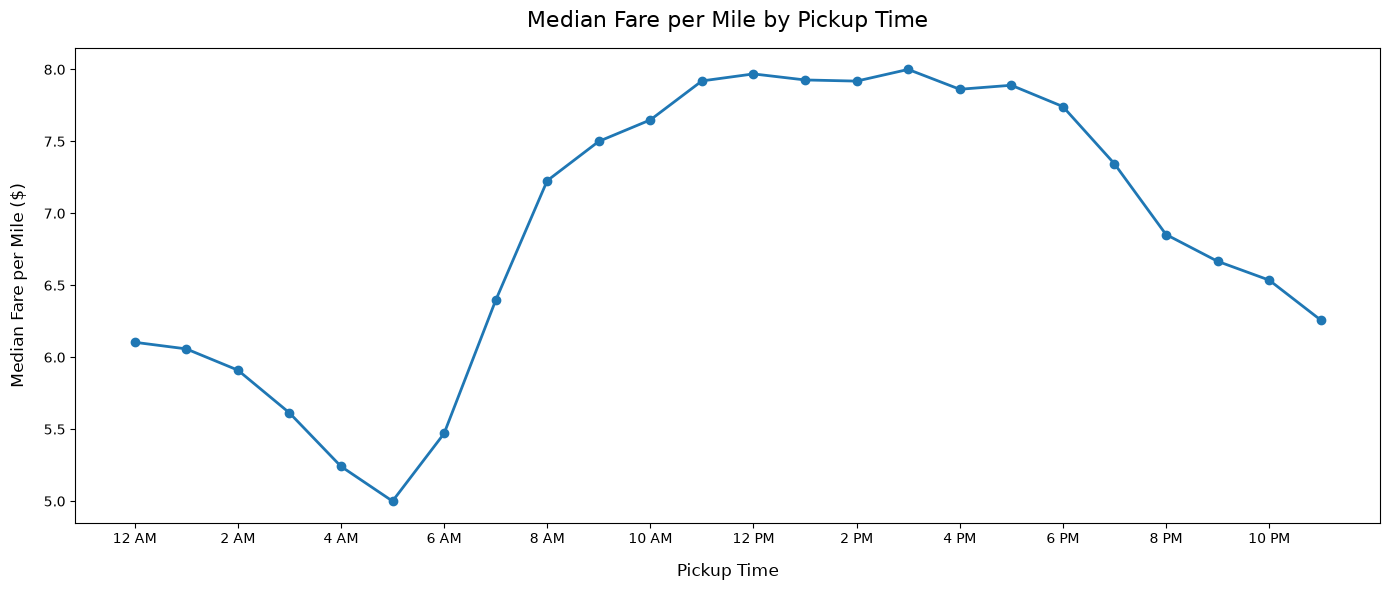

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    range(24),
    hourly["median_fare_per_mile"],
    marker="o",
    linewidth=2
)

plt.xlabel("Pickup Time", fontsize=12, labelpad=12)
plt.ylabel("Median Fare per Mile ($)", fontsize=12, labelpad=12)
plt.title("Median Fare per Mile by Pickup Time", fontsize=16, pad=15)

tick_positions = range(0, 24, 2)

tick_labels = [
    "12 AM", "2 AM", "4 AM", "6 AM", "8 AM", "10 AM",
    "12 PM", "2 PM", "4 PM", "6 PM", "8 PM", "10 PM"
]

plt.xticks(tick_positions, tick_labels, fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

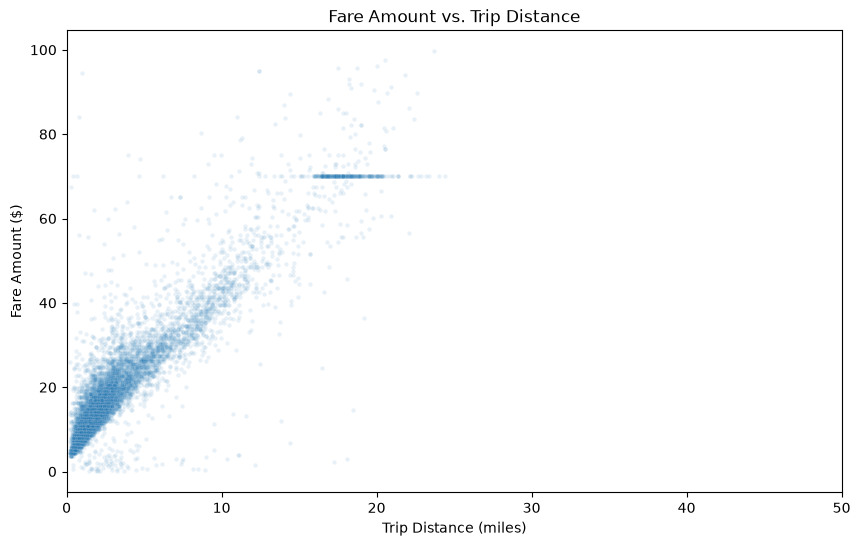

In [34]:
sample = final.sample(n=10_000, random_state=42)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample,
    x="trip_distance",
    y="fare_amount",
    alpha=0.1,
    s=10
)
plt.xlim(0, 50)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.title("Fare Amount vs. Trip Distance")
plt.show()

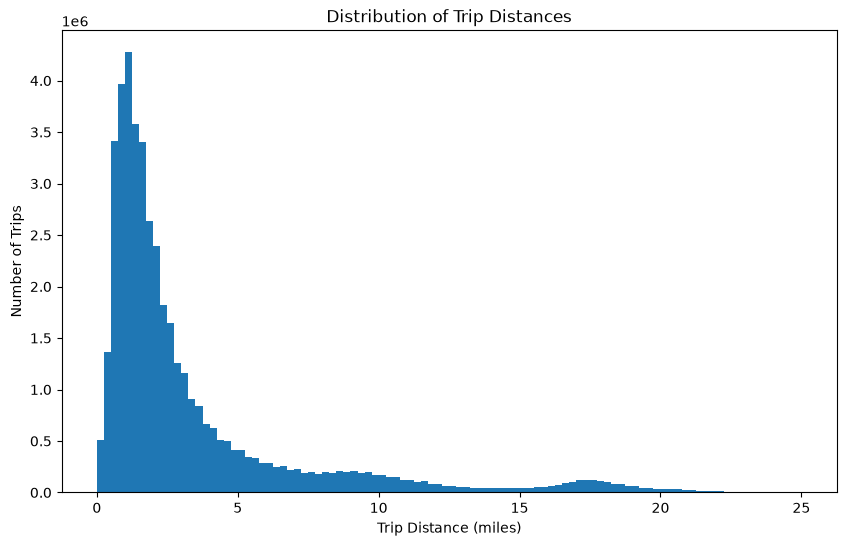

In [35]:
plt.figure(figsize=(10, 6))

plt.hist(
    clean["trip_distance"],
    bins=100,
    range=(0, 25)
)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distances")

plt.show()

Hypothesis 4: We hypothesize that our data is highly multicollinear

<Figure size 1400x1400 with 0 Axes>

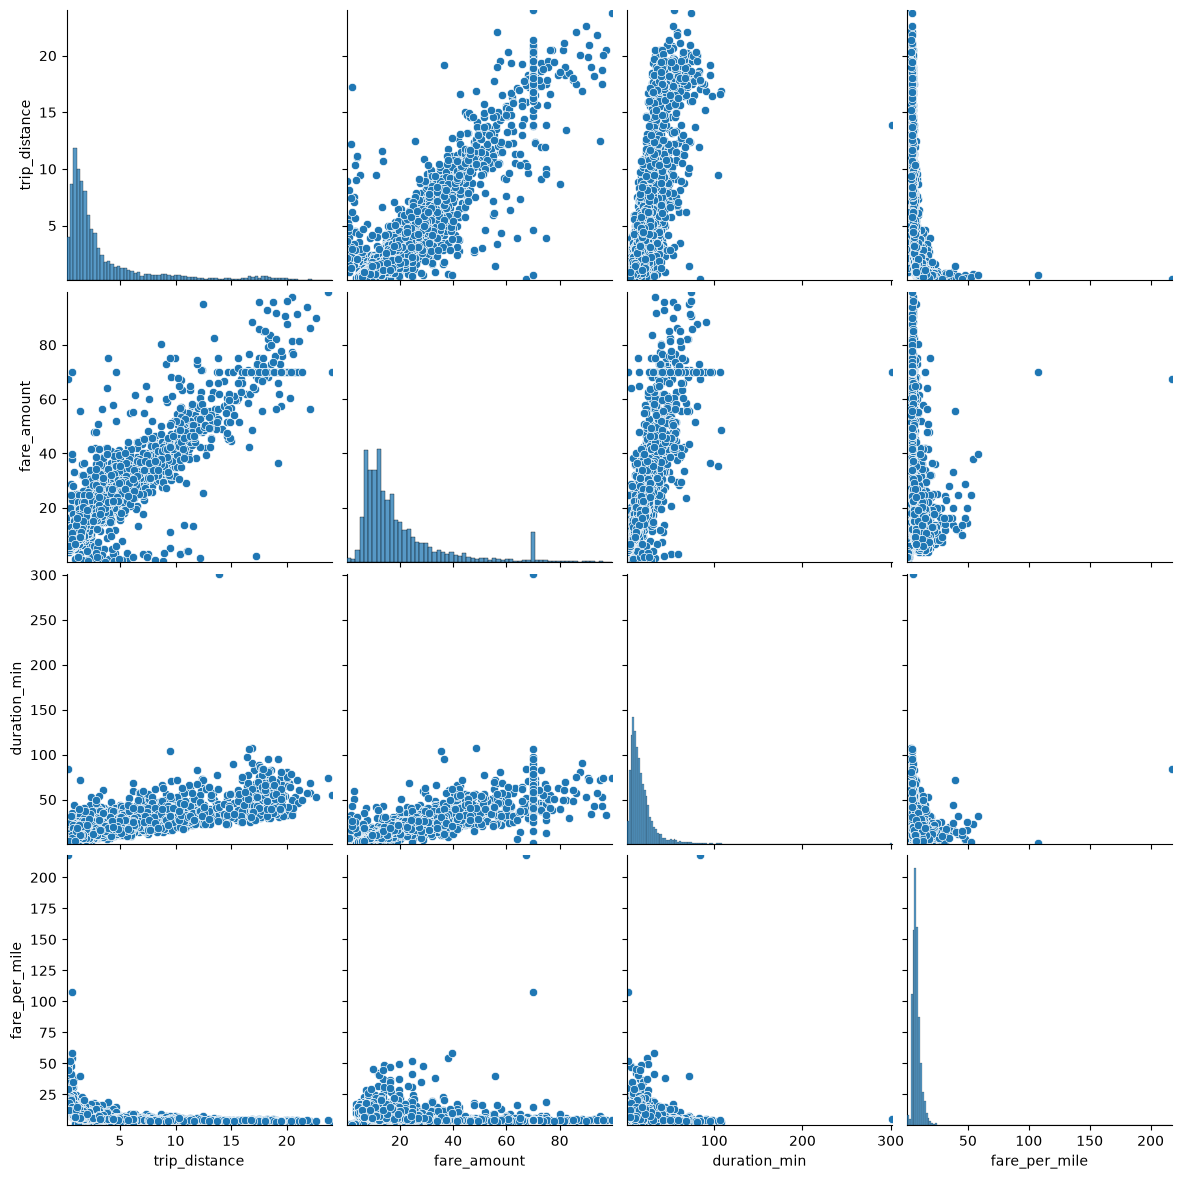

In [ ]:
plt.figure(figsize=(14, 14))
plot_df = final[
    ["trip_distance", "fare_amount", "duration_min", "fare_per_mile"]
].sample(n=5000, random_state=42)

g = sns.pairplot(plot_df, height =3)
for ax in g.axes.flat:
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

plt.show()

In [41]:
final["total_amount"] = final["fare_amount"] + final["mta_tax"] + final["tolls_amount"] + final["improvement_surcharge"]